# sweet.tv TV programme recommender: exploratory data analysis

The task is to predict, for 1,260 users, the five programmes they will watch most often in weeks 31 to 42. The competition data page defines the target: drop `tv_show_id = 0`, compute for every user and airing the watched share of the airing, keep airings watched for at least 0.8 of their length, count them per programme and take strictly the five most frequent programmes. This notebook studies the data with that target in mind. W1 means weeks 11 to 20 and W2 means weeks 21 to 30.

In [1]:
# Environment, paths and helpers
import json
import os
import platform
import sys
import time

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import scipy.sparse as sp

ROOT = os.path.abspath('..')
sys.path.insert(0, os.path.join(ROOT, 'src'))
from sweettv import data, join, target  # noqa: E402

RAW, CACHE = os.path.join(ROOT, 'data', 'raw'), os.path.join(ROOT, 'data', 'cache')
FIG = os.path.join(ROOT, 'eda', 'figures')
os.makedirs(FIG, exist_ok=True)
pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 60)
pd.set_option('display.max_colwidth', 70)
QS = [0, .01, .05, .1, .25, .5, .75, .9, .95, .99, .999, 1]
SUMMARY = {}
T0 = time.time()
as_dt = data.as_datetime
print(platform.platform(), '|', platform.processor(), '| cpus', os.cpu_count(), '| python', platform.python_version())
print('numpy', np.__version__, '| pandas', pd.__version__, '| scipy', scipy.__version__, '| matplotlib', matplotlib.__version__)


def quantiles(values, name):
    return pd.Series(np.quantile(np.asarray(values, dtype=float), QS), index=[f'q{x:g}' for x in QS], name=name)


def savefig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(FIG, f'{name}.png'), dpi=130)
    plt.show()


def ts(date):
    return int((pd.Timestamp(date) - pd.Timestamp('1970-01-01')) // pd.Timedelta(seconds=1))


def explode_top(tops):
    return tops.explode().rename('tv_show_id').reset_index().astype({'tv_show_id': 'int64'})

Windows-11-10.0.26200-SP0 | AMD64 Family 25 Model 116 Stepping 1, AuthenticAMD | cpus 16 | python 3.12.14
numpy 2.5.4 | pandas 3.0.6 | scipy 1.18.1 | matplotlib 3.11.2


## 1. Files and integrity

In [2]:
# View log: load (parsed once and cached as parquet) and check integrity
t = time.time()
views = data.load_views(RAW, CACHE)
print(f'loaded in {time.time() - t:.1f}s')
diff = views.stop - views.start - views.duraton
checks = {
    'rows': len(views),
    'users': views.user_id.nunique(),
    'channels (vsetv_id)': views.vsetv_id.nunique(),
    'null cells': int(views.isna().sum().sum()),
    'exact duplicate rows': int(views.duplicated(['user_id', 'vsetv_id', 'start', 'stop']).sum()),
    'rows where duraton differs from stop minus start': int((diff != 0).sum()),
    'max abs difference, s': int(diff.abs().max()),
    'non-positive duraton': int((views.duraton <= 0).sum()),
    'first start': str(as_dt(views.start.min())),
    'last stop': str(as_dt(views.stop.max())),
}
SUMMARY['views'] = checks
display(pd.Series(checks).to_frame('value'))
print('dates of the rows where duraton differs:', as_dt(views.start[diff != 0]).dt.date.value_counts().to_dict())
print('difference values:', diff[diff != 0].value_counts().to_dict())

loaded in 0.2s


,value
rows,5821987
users,4914
channels (vsetv_id),202
null cells,0
exact duplicate rows,17
rows where duraton differs from stop minus start,117
"max abs difference, s",3600
non-positive duraton,0
first start,2020-03-09 00:00:02
last stop,2020-07-26 23:59:58


dates of the rows where duraton differs: {datetime.date(2020, 3, 29): 115, datetime.date(2020, 3, 28): 2}
difference values: {3600: 117}


In [3]:
# Schedule: load the three files and summarise each
sched = data.load_schedule(RAW, CACHE)
print(sched.dtypes.to_string())


def part_summary(df):
    lab_rows = df[df.labelled]
    return pd.Series({
        'rows': len(df), 'labelled rows': len(lab_rows), 'labelled share of rows': round(len(lab_rows) / len(df), 4),
        'labelled share of airtime': round(lab_rows.duration.sum() / df.duration.sum(), 4),
        'channels': df.channel_id.nunique(), 'channels with any label': lab_rows.channel_id.nunique(),
        'programmes (tv_show_id)': lab_rows.tv_show_id.nunique(), 'categories': df.tv_show_category.nunique(),
        'first start': str(as_dt(df.start.min())), 'last end': str(as_dt(df.end.max())),
    })


parts = pd.DataFrame({p: part_summary(g) for p, g in sched.groupby('part')})
SUMMARY['schedule_parts'] = parts.astype(str).to_dict()
parts

channel_id            int64
channel_title           str
duration              int64
tv_show_title           str
tv_show_id            int64
tv_show_category        str
tv_show_genre_1         str
tv_show_genre_2         str
tv_show_genre_3         str
year_of_production      str
director                str
actors                  str
part                    str
start                 int64
end                   int64
labelled               bool
week                  int16


,w11_20,w21_30,w31_42
rows,1074235,1074394,1295378
labelled rows,115613,121505,144774
labelled share of rows,0.1076,0.1131,0.1118
labelled share of airtime,0.1597,0.169,0.1667
channels,400,403,404
channels with any label,177,188,191
programmes (tv_show_id),5847,6363,6636
categories,9,9,9
first start,2020-03-08 23:00:00,2020-05-18 00:00:00,2020-07-27 00:00:00
last end,2020-05-18 12:00:00,2020-07-27 12:00:00,2020-10-19 12:00:00


In [4]:
# The files overlap at their boundaries: compare the rows that two files share
rows = []
for p1, p2 in [('w11_20', 'w21_30'), ('w21_30', 'w31_42')]:
    a_, b_ = sched[sched.part == p1], sched[sched.part == p2]
    lo, hi = b_.start.min(), a_.start.max()
    m = a_[a_.start >= lo].merge(b_[b_.start <= hi], on=['channel_id', 'start'], how='outer', suffixes=('_a', '_b'), indicator=True)
    both_ = m[m['_merge'] == 'both']
    rows.append({'files': f'{p1} and {p2}', 'overlap from': str(as_dt(lo)), 'overlap to': str(as_dt(hi)),
                 'rows only in the first': int((m['_merge'] == 'left_only').sum()),
                 'rows only in the second': int((m['_merge'] == 'right_only').sum()),
                 'same channel and start': len(both_),
                 'of them same programme id': int((both_.tv_show_id_a == both_.tv_show_id_b).sum()),
                 'of them same duration': int((both_.duration_a == both_.duration_b).sum())})
pd.DataFrame(rows).set_index('files').T

files,w11_20 and w21_30,w21_30 and w31_42
overlap from,2020-05-18 00:00:00,2020-07-27 00:00:00
overlap to,2020-05-18 11:45:00,2020-07-27 11:55:00
rows only in the first,2431,2429
rows only in the second,4988,5114
same channel and start,0,0
of them same programme id,0,0
of them same duration,0,0


In [5]:
# Submission template and test users
sub = data.load_submission(RAW)
test_users = pd.Index(sub.user_id.unique())
print(sub.shape, '| unique users', len(test_users), '| template values', sub.tv_show_id.unique()[:3].tolist(),
      '| test users present in the view log', int(test_users.isin(views.user_id.unique()).sum()))

(1260, 2) | unique users 1260 | template values ['0 0 0 0 0'] | test users present in the view log 1260


## 2. Viewing behaviour

week,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30
views,407493,452314,465318,428820,412698,406317,417854,385637,336042,232680,182044,192998,162882,156928,138807,126940,105223,271172,261698,278122
users,4697,4721,4689,4666,4658,4682,4638,4599,4606,4220,3572,3562,3440,3252,3108,2406,4275,4620,4620,4565
hours,131486,143985,150052,140984,133671,132039,133168,120462,156764,126666,107765,111680,95923,96526,52378,41915,48482,164463,162282,143536


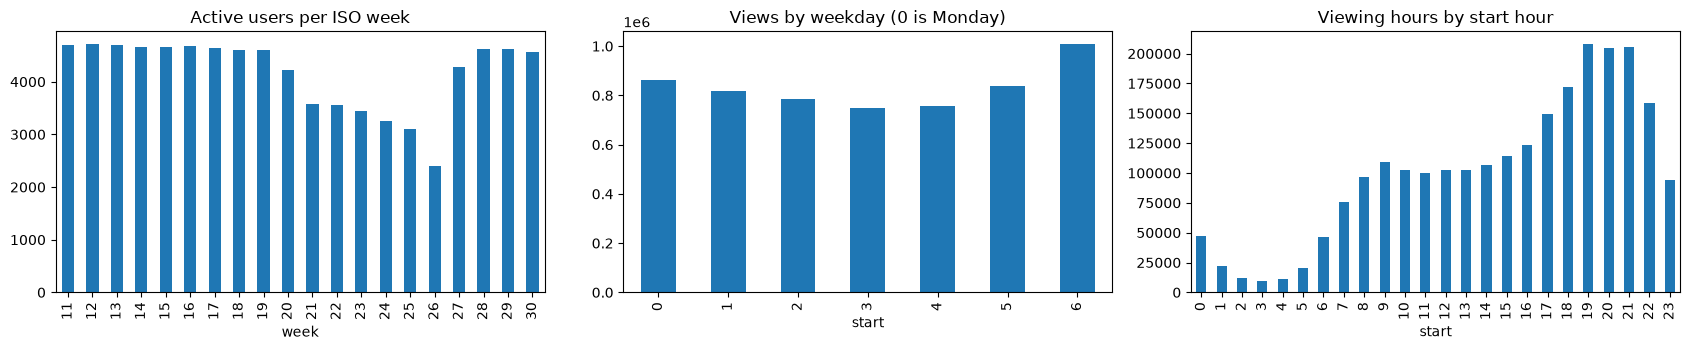

In [6]:
# Activity by ISO week, weekday and hour of day
dt = as_dt(views.start)
weekly = views.groupby('week').agg(views=('user_id', 'size'), users=('user_id', 'nunique'), seconds=('duraton', 'sum'))
weekly['hours'] = weekly.pop('seconds') / 3600
display(weekly.T.round(0).astype(int))
fig, ax = plt.subplots(1, 3, figsize=(17, 3.6))
weekly.users.plot.bar(ax=ax[0], title='Active users per ISO week')
dt.dt.dayofweek.value_counts().sort_index().plot.bar(ax=ax[1], title='Views by weekday (0 is Monday)')
(views.groupby(dt.dt.hour).duraton.sum() / 3600).plot.bar(ax=ax[2], title='Viewing hours by start hour')
savefig('views_by_time')
del dt

days without a single view: ['2020-07-03']


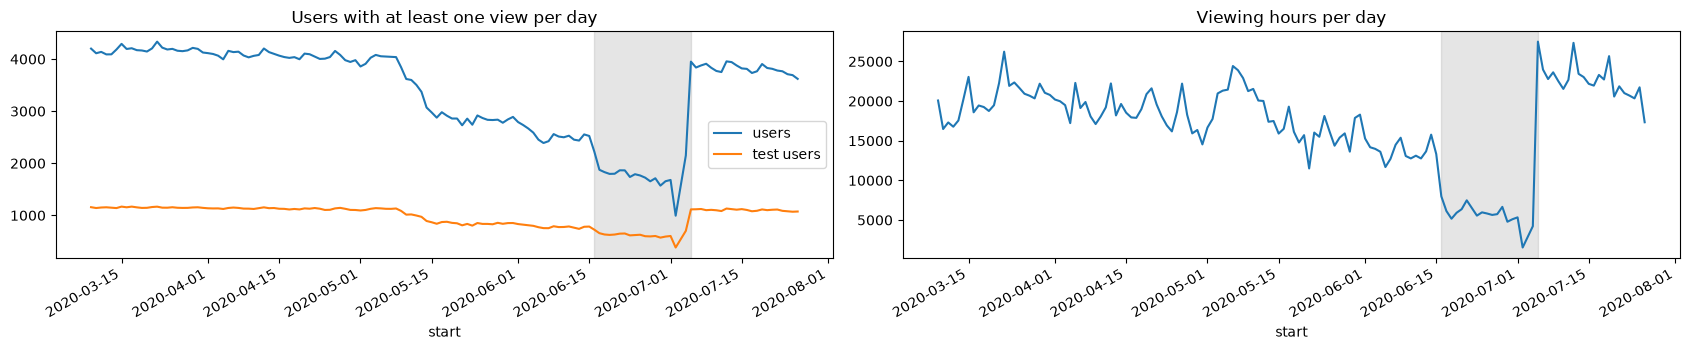

"mean per day, end date excluded",2020-03-09 to 2020-05-13,2020-05-13 to 2020-06-16,2020-06-16 to 2020-07-05,2020-07-05 to 2020-07-27
users,4073.0,2740.0,1760.0,3816.0
test users,1130.0,823.0,616.0,1102.0
hours,19734.0,15053.0,5664.0,22626.0
views,58337.0,25592.0,16898.0,38899.0


users active before 2020-06-16 and after 2020-07-05 but without any view in between: 1129 of 4727 (0.239), test users among them 188


In [7]:
# Daily activity: a logging gap in June and early July
day = as_dt(views.start).dt.normalize()
daily = views.groupby(day).agg(users=('user_id', 'nunique'), hours=('duraton', 'sum'), views=('user_id', 'size'))
daily['hours'] = daily.hours / 3600
daily['test users'] = views[views.user_id.isin(test_users)].groupby(day[views.user_id.isin(test_users)]).user_id.nunique()
full_days = pd.date_range(as_dt(views.start.min()).normalize(), as_dt(views.start.max()).normalize())
print('days without a single view:', [str(d_.date()) for d_ in full_days.difference(daily.index)])
fig, ax = plt.subplots(1, 2, figsize=(17, 3.6))
daily[['users', 'test users']].plot(ax=ax[0], title='Users with at least one view per day')
daily.hours.plot(ax=ax[1], title='Viewing hours per day')
for a_ in ax:
    a_.axvspan(pd.Timestamp('2020-06-16'), pd.Timestamp('2020-07-05'), color='grey', alpha=0.2)
savefig('daily_activity')
cuts_ = ['2020-03-09', '2020-05-13', '2020-06-16', '2020-07-05', '2020-07-27']
display(pd.DataFrame({f'{a_} to {b_}': daily[(daily.index >= a_) & (daily.index < b_)][['users', 'test users', 'hours', 'views']].mean()
                      for a_, b_ in zip(cuts_[:-1], cuts_[1:])}).round(0).rename_axis(columns='mean per day, end date excluded'))
before = set(views.user_id[views.start < ts('2020-06-16')])
after = set(views.user_id[views.start >= ts('2020-07-05')])
inside = set(views.user_id[(views.start >= ts('2020-06-16')) & (views.start < ts('2020-07-05'))])
gap_users = (before & after) - inside
print(f'users active before 2020-06-16 and after 2020-07-05 but without any view in between: {len(gap_users)} '
      f'of {len(before & after)} ({len(gap_users) / len(before & after):.3f}), test users among them {len(gap_users & set(test_users))}')
SUMMARY['logging_gap'] = {'days_without_views': [str(d_.date()) for d_ in full_days.difference(daily.index)],
                          'users_missing_in_gap': len(gap_users), 'users_before_and_after': len(before & after)}
del day

,q0,q0.01,q0.05,q0.1,q0.25,q0.5,q0.75,q0.9,q0.95,q0.99,q0.999,q1
seconds,61.0,62.0,69.0,80.0,133.0,396.0,1452.0,3911.0,6344.0,14079.14,33976.0,342145.0


,10,30,60,120,300,600,1800,3600,14400,86400
share of views below,0.0,0.0,0.0,0.222,0.440,0.584,0.787,0.889,0.990,1.000
share of viewing time below,0.0,0.0,0.0,0.013,0.041,0.083,0.230,0.408,0.852,0.999


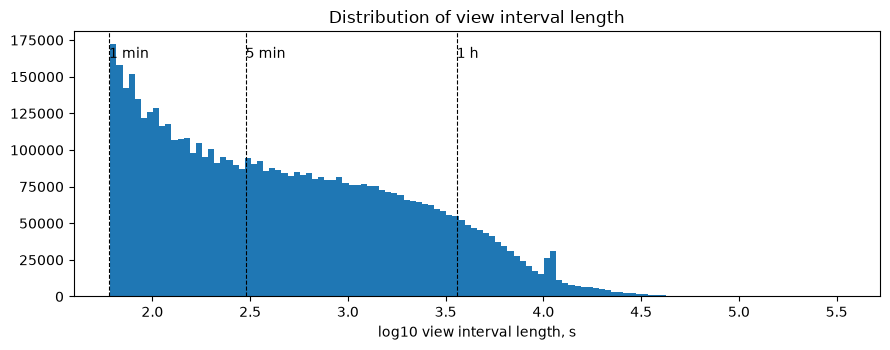

In [8]:
# Length of a viewing interval in seconds
d = views.duraton
display(quantiles(d, 'seconds').to_frame().T)
cuts = [10, 30, 60, 120, 300, 600, 1800, 3600, 4 * 3600, 24 * 3600]
display(pd.DataFrame({'share of views below': [(d < c).mean() for c in cuts],
                      'share of viewing time below': [d[d < c].sum() / d.sum() for c in cuts]}, index=cuts).T.round(3))
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(np.log10(d.clip(lower=1)), bins=120)
for c, label in [(60, '1 min'), (300, '5 min'), (3600, '1 h')]:
    ax.axvline(np.log10(c), color='k', ls='--', lw=0.8)
    ax.text(np.log10(c), ax.get_ylim()[1] * 0.9, label)
ax.set_xlabel('log10 view interval length, s')
ax.set_title('Distribution of view interval length')
savefig('view_duration')

,0.000,0.010,0.050,0.100,0.250,0.500,0.750,0.900,0.950,0.990,0.999,1.000
n_views,1.00,29.00,125.65,223.30,476.00,874.00,1547.00,2429.70,3170.70,5348.31,9094.15,38114.00
hours,0.02,10.72,53.49,98.43,206.90,393.45,656.70,973.94,1207.37,1852.14,3411.66,13374.82
hours_per_active_week,0.02,1.38,4.40,6.88,12.95,22.96,36.41,52.56,63.21,94.73,170.58,743.05
n_channels,1.00,11.00,24.00,33.00,44.00,57.00,73.00,89.00,101.00,123.00,159.09,188.00
n_weeks,1.00,3.00,10.00,13.00,14.00,19.00,20.00,20.00,20.00,20.00,20.00,20.00
top_channel_share,0.06,0.08,0.11,0.12,0.15,0.20,0.26,0.35,0.42,0.60,1.00,1.00


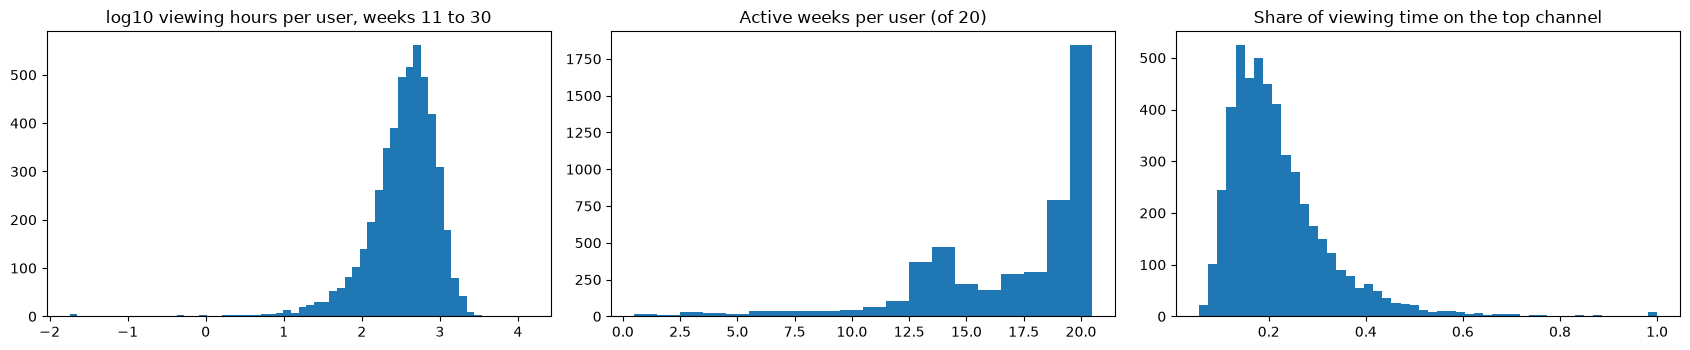

views that start before an earlier view of the same user has stopped: 0.1193
users watching more than 12 hours per active day on average: 76


In [9]:
# Activity per user
per_user = views.groupby('user_id').agg(n_views=('duraton', 'size'), seconds=('duraton', 'sum'),
                                        n_channels=('vsetv_id', 'nunique'), n_weeks=('week', 'nunique'),
                                        first_week=('week', 'min'), last_week=('week', 'max'))
per_user['hours'] = per_user.seconds / 3600
per_user['hours_per_active_week'] = per_user.hours / per_user.n_weeks
ch_time = views.groupby(['user_id', 'vsetv_id']).duraton.sum()
per_user['top_channel_share'] = ch_time.groupby(level=0).max() / ch_time.groupby(level=0).sum()
cols = ['n_views', 'hours', 'hours_per_active_week', 'n_channels', 'n_weeks', 'top_channel_share']
display(per_user[cols].quantile(QS).T.round(2))
fig, ax = plt.subplots(1, 3, figsize=(17, 3.6))
ax[0].hist(np.log10(per_user.hours), bins=60)
ax[0].set_title('log10 viewing hours per user, weeks 11 to 30')
ax[1].hist(per_user.n_weeks, bins=np.arange(0.5, 21.5))
ax[1].set_title('Active weeks per user (of 20)')
ax[2].hist(per_user.top_channel_share, bins=50)
ax[2].set_title('Share of viewing time on the top channel')
savefig('per_user')
v = views[['user_id', 'start', 'stop']].sort_values(['user_id', 'start'])
prev_stop = v.groupby('user_id').stop.cummax().shift()
concurrent = v.user_id.eq(v.user_id.shift()) & (v.start < prev_stop)
print('views that start before an earlier view of the same user has stopped:', round(concurrent.mean(), 4))
print('users watching more than 12 hours per active day on average:', int((per_user.hours / (per_user.n_weeks * 7) > 12).sum()))
del v, prev_stop, concurrent

In [10]:
# Concentration of viewing time over channels
ch_view = views.groupby('vsetv_id').agg(seconds=('duraton', 'sum'), users=('user_id', 'nunique')).sort_values('seconds', ascending=False)
cum = ch_view.seconds.cumsum() / ch_view.seconds.sum()
print({f'top {k} channels': round(cum.iloc[k - 1], 3) for k in [1, 5, 10, 20, 50, 100]})

{'top 1 channels': np.float64(0.129), 'top 5 channels': np.float64(0.392), 'top 10 channels': np.float64(0.558), 'top 20 channels': np.float64(0.709), 'top 50 channels': np.float64(0.888), 'top 100 channels': np.float64(0.981)}


In [11]:
# Test users against all users
tu = per_user[per_user.index.isin(test_users)]
display(pd.DataFrame({'test users, median': tu[cols].median(), 'all users, median': per_user[cols].median(),
                      'test users, mean': tu[cols].mean(), 'all users, mean': per_user[cols].mean()}).T.round(2))
display(pd.DataFrame({'test users': tu.last_week.value_counts().sort_index(),
                      'all users': per_user.last_week.value_counts().sort_index()})
        .fillna(0).astype(int).T.rename_axis(columns='last active week'))
SUMMARY['test_users'] = {'n': len(test_users), 'in_view_log': len(tu)}

,n_views,hours,hours_per_active_week,n_channels,n_weeks,top_channel_share
"test users, median",1377.00,536.52,29.87,71.00,20.00,0.18
"all users, median",874.00,393.45,22.96,57.00,19.00,0.20
"test users, mean",1724.85,646.33,35.22,73.11,17.90,0.19
"all users, mean",1184.78,487.23,27.37,59.41,17.01,0.22


last active week,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30
test users,0,0,4,2,1,3,3,0,1,0,1,0,0,0,1,4,1,6,17,1216
all users,2,1,10,10,4,15,18,9,12,13,5,6,9,7,18,13,12,49,136,4565


## 3. Schedule and programmes

week,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43
rows,86.000,106036.000,108177.000,107363.000,106527.000,108126.000,107697.000,107721.000,107505.000,105473.000,107093.000,107229.000,107274.000,107657.000,107449.000,107104.000,107544.000,106878.000,107528.000,107640.000,108093.000,108148.000,108256.00,107039.000,106862.000,107028.000,107492.000,107558.000,108258.000,108512.000,108763.000,108843.000,108649.000,2399.000
labelled_rows,21.000,11150.000,11325.000,11483.000,11119.000,11887.000,11416.000,12066.000,11224.000,11729.000,11910.000,11371.000,12144.000,11929.000,12001.000,12155.000,12604.000,12541.000,12000.000,12686.000,12090.000,12328.000,11911.00,11646.000,11619.000,12728.000,12376.000,11738.000,12062.000,11992.000,11870.000,12199.000,12315.000,257.000
labelled share of rows,0.244,0.105,0.105,0.107,0.104,0.110,0.106,0.112,0.104,0.111,0.111,0.106,0.113,0.111,0.112,0.113,0.117,0.117,0.112,0.118,0.112,0.114,0.11,0.109,0.109,0.119,0.115,0.109,0.111,0.111,0.109,0.112,0.113,0.107
labelled share of airtime,0.241,0.152,0.150,0.155,0.152,0.158,0.151,0.174,0.155,0.178,0.171,0.156,0.174,0.163,0.167,0.170,0.177,0.179,0.162,0.180,0.162,0.177,0.16,0.164,0.160,0.185,0.177,0.159,0.162,0.160,0.159,0.168,0.169,0.153
programmes airing,11.000,1419.000,1300.000,1362.000,1386.000,1490.000,1415.000,1766.000,1555.000,1903.000,1784.000,1510.000,1820.000,1650.000,1707.000,1694.000,1895.000,1890.000,1622.000,1971.000,1638.000,1933.000,1624.00,1707.000,1615.000,2059.000,1885.000,1627.000,1577.000,1600.000,1508.000,1741.000,1712.000,136.000


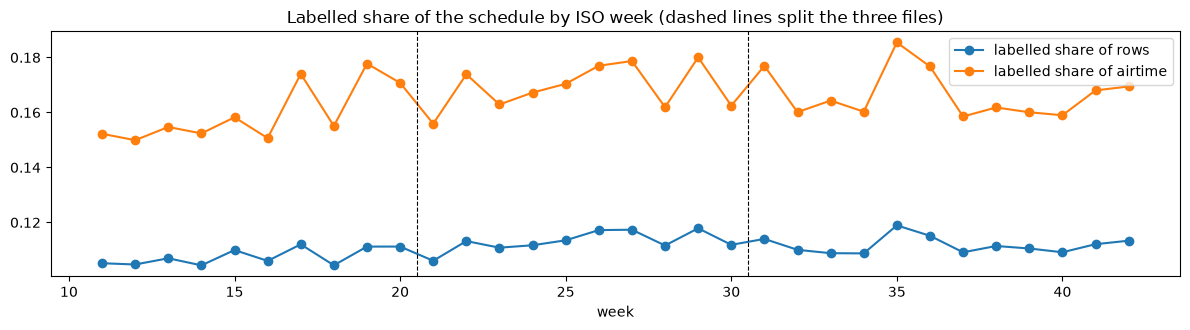

In [12]:
# Labelled share of schedule rows and airtime per ISO week
slots_all = data.unique_slots(sched)
wk = slots_all.groupby('week').agg(rows=('labelled', 'size'), labelled_rows=('labelled', 'sum'))
wk['labelled share of rows'] = wk.labelled_rows / wk.rows
wk['labelled share of airtime'] = (slots_all[slots_all.labelled].groupby('week').duration.sum()
                                   / slots_all.groupby('week').duration.sum())
wk['programmes airing'] = slots_all[slots_all.labelled].groupby('week').tv_show_id.nunique()
display(wk.T.round(3))
fig, ax = plt.subplots(figsize=(12, 3.4))
wk.loc[11:42, ['labelled share of rows', 'labelled share of airtime']].plot(ax=ax, marker='o')
ax.axvline(20.5, color='k', ls='--', lw=0.8)
ax.axvline(30.5, color='k', ls='--', lw=0.8)
ax.set_title('Labelled share of the schedule by ISO week (dashed lines split the three files)')
savefig('labelled_share_by_week')

In [13]:
# Slot lengths in minutes, gaps and overlaps inside each channel grid
print('non-positive durations', int((slots_all.duration <= 0).sum()), '| null titles', int(slots_all.tv_show_title.isna().sum()),
      '| duplicate (channel, start) after removing exact repeats', int(slots_all.duplicated(['channel_id', 'start']).sum()))
display(pd.DataFrame({'labelled': quantiles(slots_all.duration[slots_all.labelled] / 60, 'labelled'),
                      'unlabelled': quantiles(slots_all.duration[~slots_all.labelled] / 60, 'unlabelled')}).T.round(1))
g = slots_all.sort_values(['channel_id', 'start'])
gap = (g.groupby('channel_id').start.shift(-1) - g.end).dropna()
print('consecutive slots: contiguous', round((gap == 0).mean(), 4), '| gap', round((gap > 0).mean(), 4),
      '| overlap', round((gap < 0).mean(), 4))
display(pd.DataFrame({'gaps, min': quantiles(gap[gap > 0] / 60, 'gaps'),
                      'overlaps, min': quantiles(-gap[gap < 0] / 60, 'overlaps')}).T.round(1))
del g, gap

non-positive durations 1 | null titles 0 | duplicate (channel, start) after removing exact repeats 1


,q0,q0.01,q0.05,q0.1,q0.25,q0.5,q0.75,q0.9,q0.95,q0.99,q0.999,q1
labelled,1.0,4.0,5.0,10.0,20.0,45.0,90.0,120.0,140.0,225.0,360.0,545.0
unlabelled,0.0,1.0,3.0,4.0,10.0,25.0,45.0,65.0,110.0,215.0,480.0,1440.0


consecutive slots: contiguous 0.9999 | gap 0.0001 | overlap 0.0


,q0,q0.01,q0.05,q0.1,q0.25,q0.5,q0.75,q0.9,q0.95,q0.99,q0.999,q1
"gaps, min",5.0,30.9,60.0,60.0,60.0,60.0,60.0,60.0,60.0,64.8,32195.5,40320.0
"overlaps, min",2.0,2.4,3.8,6.0,25.0,40.0,60.0,252.0,300.0,300.0,300.0,300.0


In [14]:
# One row per programme: attributes and their consistency
lab = slots_all[slots_all.labelled]
prog = lab.groupby('tv_show_id').agg(
    title=('tv_show_title', 'first'), n_titles=('tv_show_title', 'nunique'),
    category=('tv_show_category', 'first'), n_categories=('tv_show_category', 'nunique'),
    genre_1=('tv_show_genre_1', 'first'), genre_2=('tv_show_genre_2', 'first'), genre_3=('tv_show_genre_3', 'first'),
    year=('year_of_production', 'first'), director=('director', 'first'), actors=('actors', 'first'),
    n_airings=('start', 'size'), n_channels=('channel_id', 'nunique'), median_slot_min=('duration', 'median'))
prog['median_slot_min'] = prog.median_slot_min / 60
print('programmes', len(prog), '| more than one title', int((prog.n_titles > 1).sum()),
      '| more than one category', int((prog.n_categories > 1).sum()),
      '| airing on more than one channel', int((prog.n_channels > 1).sum()))
display(prog[['genre_1', 'genre_2', 'genre_3', 'year', 'director', 'actors']].notna().mean().to_frame('filled share').T.round(3))
display(pd.DataFrame({'airings per programme': quantiles(prog.n_airings, 'a'),
                      'median slot minutes': quantiles(prog.median_slot_min, 'b')}).T.round(1))
for pid in prog.sort_values('n_titles', ascending=False).head(3).index:
    print(pid, prog.n_titles[pid], lab.tv_show_title[lab.tv_show_id == pid].drop_duplicates().head(4).tolist())
title_ids = lab.groupby('tv_show_title').tv_show_id.nunique()
print('titles carried by more than one id:', int((title_ids > 1).sum()), 'of', len(title_ids))

programmes 9671 | more than one title 4351 | more than one category 0 | airing on more than one channel 4644


,genre_1,genre_2,genre_3,year,director,actors
filled share,0.976,0.6,0.224,0.999,0.981,0.985


,q0,q0.01,q0.05,q0.1,q0.25,q0.5,q0.75,q0.9,q0.95,q0.99,q0.999,q1
airings per programme,1.0,1.0,1.0,1.0,2.0,6.0,16.0,36.0,72.0,593.5,4246.3,19024.0
median slot minutes,3.0,25.0,58.8,75.0,90.0,105.0,120.0,155.0,195.0,250.0,386.6,465.0


10002000 1209 ["Премьера. Т/с 'След'. 'Наемник в белом воротничке'.", "Премьера. Т/с 'След'. 'Временные трудности'.", "Премьера. Т/с 'След'. 'На пике формы'.", "Премьера. Т/с 'След'. 'Ко мне, Петрович!'."]
12001682 936 ["М/с 'Губка Боб Квадратные Штаны'.", "М/с 'Губка Боб Квадратные Штаны', 225 с. 'Пуши Обнимаш / Гарцующий Патрик'.", "М/с 'Губка Боб Квадратные Штаны', 75 с. 'Сквидивительный вояж / Милашка'.", "М/с 'Губка Боб Квадратные Штаны', 224 с. 'Сквидвард, частный сыщик / Ищи, пока не найдёшь'."]
12001712 761 ["М/с 'Симпсоны', 14 сезон, 4 с.", "М/с 'Симпсоны', 24 сезон, 17 с.", "Хиты нон-стоп. М/с 'Симпсоны', 29 сезон, 20 с.", "Хиты нон-стоп. М/с 'Симпсоны', 29 сезон, 21 с."]
titles carried by more than one id: 284 of 48476


In [15]:
# Categories, genres, years and people
cat_air = lab.groupby(['tv_show_category', 'part']).duration.sum().unstack()
display(pd.concat({'programmes': prog.category.value_counts(),
                   'labelled airtime share': (cat_air / cat_air.sum()).round(3)}, axis=1))
genres = pd.concat([prog.genre_1, prog.genre_2, prog.genre_3]).dropna().value_counts()
print('distinct genres', len(genres), '| programmes with at least one genre', round(prog.genre_1.notna().mean(), 3))
display(genres.head(25).to_frame('programmes').T)
years = pd.to_numeric(prog.year.str.extract(r'(\d{4})')[0], errors='coerce')
print('programmes with a parsable year', round(years.notna().mean(), 3), '| open-ended periods like "1996-"',
      int(prog.year.str.endswith('-', na=False).sum()))
display(quantiles(years.dropna(), 'year of production').to_frame().T)
for col in ['director', 'actors']:
    names = prog[col].dropna().str.split(',').explode().str.strip()
    per_name = names.value_counts()
    print(f'{col}: programmes with it {prog[col].notna().sum()}, distinct names {len(per_name)}, '
          f'names on more than one programme {int((per_name > 1).sum())}')

programmes labelled airtime share              
                    count                 w11_20 w21_30 w31_42
Фильмы               8197                  0.391  0.425  0.423
Сериалы               748                  0.306  0.288  0.296
Детям                 581                  0.169  0.153  0.149
Развлечения            67                  0.072  0.066  0.066
Познавательное         47                  0.030  0.039  0.036
Инфо                   19                  0.027  0.026  0.026
Другое                  9                  0.004  0.003  0.003
Спорт                   3                  0.000  0.000  0.000

distinct genres 65 | programmes with at least one genre 0.976


,драма,комедия,мелодрама,приключения,боевик,триллер,фантазия,детектив,криминал,фантастика,ужастик,военный,биографический,исторический,музыкальный,спортивный,мистика,киноповесть,вестерн,мюзикл,развлекательные,юмор,взаимоотношения,общество и политика,реальные истории
programmes,3146,2954,2016,1633,1503,1171,821,776,696,601,372,308,300,231,200,140,123,83,50,30,23,22,20,19,15


programmes with a parsable year 0.999 | open-ended periods like "1996-" 199


,q0,q0.01,q0.05,q0.1,q0.25,q0.5,q0.75,q0.9,q0.95,q0.99,q0.999,q1
year of production,0.0,1949.56,1969.0,1980.0,1998.0,2009.0,2015.0,2017.0,2018.0,2019.0,2020.0,2020.0


director: programmes with it 9488, distinct names 4793, names on more than one programme 1773
actors: programmes with it 9524, distinct names 12354, names on more than one programme 4274


In [16]:
# Unlabelled airtime: what it carries and whether its titles match labelled programmes
def norm(s):
    return s.fillna('').str.lower().str.replace(r'[^0-9a-zа-яёіїєґ]+', ' ', regex=True).str.strip()


unl = slots_all[~slots_all.labelled]
unl_norm = norm(unl.tv_show_title)
match = unl_norm.isin(set(norm(lab.tv_show_title)))
print('unlabelled rows whose normalised title equals a labelled title:', round(match.mean(), 4),
      '| share of unlabelled airtime', round(unl.duration[match].sum() / unl.duration.sum(), 4))
display((unl.groupby('tv_show_category', dropna=False).duration.sum() / unl.duration.sum()).sort_values(ascending=False)
        .round(3).to_frame('share of unlabelled airtime').T)
print('unlabelled rows with any genre', round(unl.tv_show_genre_1.notna().mean(), 4),
      '| with a year', round(unl.year_of_production.notna().mean(), 4))
top_unl = unl.groupby(unl_norm).agg(seconds=('duration', 'sum'), rows=('duration', 'size'), channels=('channel_id', 'nunique'))
top_unl['hours'] = top_unl.pop('seconds') / 3600
display(top_unl.sort_values('hours', ascending=False).head(15).round(0))
del unl, unl_norm, match

unlabelled rows whose normalised title equals a labelled title: 0.0158 | share of unlabelled airtime 0.0438


tv_show_category,Другое,Познавательное,Спорт,Музыка,Фильмы,Сериалы,Детям,Инфо,Развлечения
share of unlabelled airtime,0.423,0.193,0.122,0.077,0.062,0.059,0.033,0.028,0.003


unlabelled rows with any genre 0.3606 | with a year 0.0


,rows,channels,hours
tv_show_title,,,
новости,37457,36,10474.0
телемагазин,13942,25,6915.0
мультфильмы,4528,19,6901.0
ночной эфир,1365,10,6375.0
первый немецкий телемагазин,1344,1,5376.0
top mix,672,1,5376.0
ювелірний телемагазин,672,1,5375.0
наші золоті хіти,5375,1,5375.0
хиты прошлых лет,672,1,5375.0


In [17]:
# Channels: labelled airtime share per channel and the match with the view log
train_slots = slots_all[slots_all.part != 'w31_42']
ch = pd.DataFrame({'title': train_slots.groupby('channel_id').channel_title.first(),
                   'airtime': train_slots.groupby('channel_id').duration.sum(),
                   'labelled_airtime': train_slots[train_slots.labelled].groupby('channel_id').duration.sum()})
ch['labelled_airtime'] = ch.labelled_airtime.fillna(0)
ch['labelled_share'] = ch.labelled_airtime / ch.airtime
print('training channels', len(ch), '| with no labelled slot', int((ch.labelled_share == 0).sum()))
in_sched = ch_view.index.isin(ch.index)
print('view-log channels', len(ch_view), '| present in the schedule', int(in_sched.sum()),
      '| share of viewing time on them', round(ch_view.seconds[in_sched].sum() / ch_view.seconds.sum(), 4))
top_ch = ch_view.head(20).join(ch[['title', 'labelled_share']])
top_ch['share of viewing time'] = top_ch.seconds / ch_view.seconds.sum()
display(top_ch[['title', 'share of viewing time', 'users', 'labelled_share']].round(3))
w = ch_view.seconds[in_sched]
print('viewing-time-weighted labelled airtime share of the watched channels',
      round(float((ch.labelled_share.reindex(w.index) * w).sum() / w.sum()), 4))

training channels 404 | with no labelled slot 213
view-log channels 202 | present in the schedule 197 | share of viewing time on them 0.9865


,title,share of viewing time,users,labelled_share
vsetv_id,,,,
3,1+1,0.129,4805,0.734
5,ICTV,0.083,4743,0.666
6,СТБ,0.062,4637,0.690
7,Новый канал,0.060,4701,0.804
108,Украина,0.058,4579,0.816
4,Интер,0.044,4594,0.635
1521,TV1000 Action CEE,0.040,4625,0.999
1516,TV1000 CEE,0.029,4571,0.999
921,112 Украина,0.026,4405,0.019


viewing-time-weighted labelled airtime share of the watched channels 0.5635


## 4. Joining views to the schedule

best shift of the view clock, hours: 0.0 | stop hit rate there 0.0477 | median over all shifts 0.0346


best whole-hour shift per week: {11: 0, 12: 0, 13: 0, 14: 0, 15: 0, 16: 0, 17: 0, 18: 0, 19: 0, 20: 0, 21: 0, 22: 0, 23: 0, 24: 0, 25: 0, 26: 0, 27: 0, 28: 0, 29: 0, 30: 0}


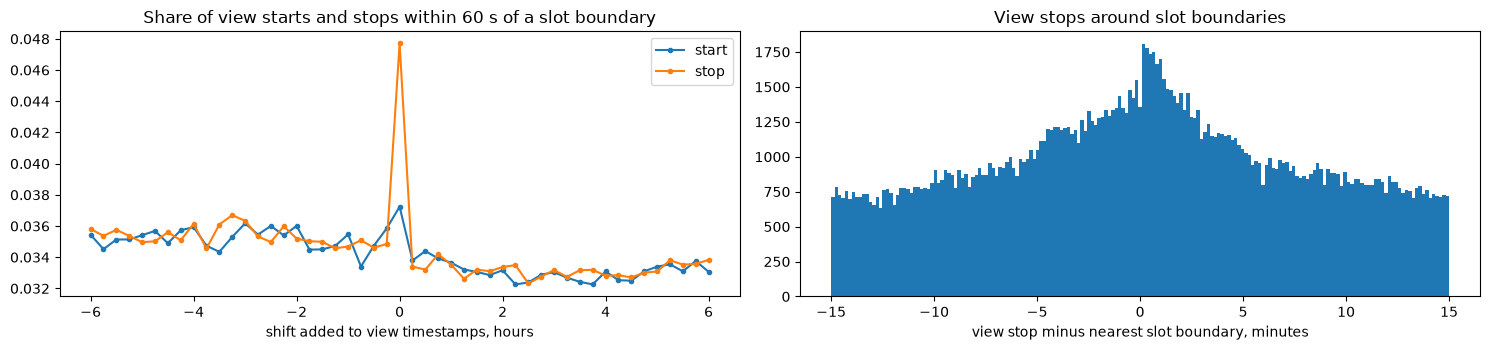

In [18]:
# Time alignment: share of view starts and stops within 60 s of a slot boundary, for shifted view clocks
codes = join.channel_codes(slots_all.channel_id)
b_code = join.encode(train_slots.channel_id, codes)
bounds = np.unique(np.concatenate([b_code * join.BIG + train_slots.start.to_numpy(), b_code * join.BIG + train_slots.end.to_numpy()]))
samp = views[views.vsetv_id.isin(codes.index)].sample(400_000, random_state=0)
s_code = join.encode(samp.vsetv_id, codes)


def signed_offset(t, c):
    key = c * join.BIG + t
    i = np.searchsorted(bounds, key).clip(1, len(bounds) - 1)
    after, before = bounds[i] - key, key - bounds[i - 1]
    return np.where(after < before, -after, before)


def hit_rate(t, c, tol=60):
    return float((np.abs(signed_offset(t, c)) <= tol).mean())


shifts = np.arange(-6, 6.25, 0.25)
align = pd.DataFrame({'start': [hit_rate(samp.start.to_numpy() + int(h * 3600), s_code) for h in shifts],
                      'stop': [hit_rate(samp.stop.to_numpy() + int(h * 3600), s_code) for h in shifts]}, index=shifts)
print('best shift of the view clock, hours:', align.stop.idxmax(), '| stop hit rate there', round(align.stop.max(), 4),
      '| median over all shifts', round(align.stop.median(), 4))
best_by_week = {int(wn): max(range(-3, 4), key=lambda h: hit_rate(samp.stop.to_numpy()[idx] + h * 3600, s_code[idx]))
                for wn, idx in samp.groupby('week').indices.items()}
print('best whole-hour shift per week:', best_by_week)
fig, ax = plt.subplots(1, 2, figsize=(15, 3.6))
align.plot(ax=ax[0], marker='.')
ax[0].set_xlabel('shift added to view timestamps, hours')
ax[0].set_title('Share of view starts and stops within 60 s of a slot boundary')
off = signed_offset(samp.stop.to_numpy(), s_code)
ax[1].hist(off[np.abs(off) <= 900] / 60, bins=181)
ax[1].set_xlabel('view stop minus nearest slot boundary, minutes')
ax[1].set_title('View stops around slot boundaries')
savefig('time_alignment')
SUMMARY['alignment'] = {'best_shift_hours': float(align.stop.idxmax()), 'stop_hit_best': align.stop.max(),
                        'stop_hit_median': align.stop.median(), 'best_shift_by_week': best_by_week}
del samp, s_code, bounds

In [19]:
# Join every view to every training slot on the same channel with positive overlap
t = time.time()
vi, si, ov = join.overlap_join(join.encode(views.vsetv_id, codes), views.start.to_numpy(), views.stop.to_numpy(),
                               join.encode(train_slots.channel_id, codes), train_slots.start.to_numpy(), train_slots.end.to_numpy())
is_lab = train_slots.labelled.to_numpy()[si]
print(f'join done in {time.time() - t:.1f}s: {len(vi):,} view-slot pairs, {int(is_lab.sum()):,} of them labelled')
any_slot = np.bincount(vi, minlength=len(views)) > 0
any_lab = np.bincount(vi[is_lab], minlength=len(views)) > 0
total = views.duraton.sum()
join_stats = {
    'views overlapping any slot': float(any_slot.mean()),
    'views overlapping a labelled slot': float(any_lab.mean()),
    'viewing time inside any slot': float(ov.sum() / total),
    'viewing time inside labelled slots': float(ov[is_lab].sum() / total),
    'users with any labelled overlap': float(views.user_id[any_lab].nunique() / views.user_id.nunique()),
    'test users with any labelled overlap': int(pd.Index(views.user_id[any_lab].unique()).isin(test_users).sum()),
}
SUMMARY['join'] = join_stats
display(pd.Series(join_stats).to_frame('value').round(4))
lab_week = pd.Series(ov[is_lab]).groupby(views.week.to_numpy()[vi[is_lab]]).sum()
display((lab_week / views.groupby('week').duraton.sum()).round(3).to_frame('labelled share of viewing time').T)
del vi, si, ov, is_lab, any_slot, any_lab

join done in 2.0s: 7,752,433 view-slot pairs, 3,847,696 of them labelled


,value
views overlapping any slot,0.9290
views overlapping a labelled slot,0.5092
viewing time inside any slot,0.9407
viewing time inside labelled slots,0.5308
users with any labelled overlap,0.9961
test users with any labelled overlap,1258.0000


,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30
labelled share of viewing time,0.44,0.458,0.463,0.477,0.486,0.475,0.474,0.567,0.565,0.581,0.595,0.563,0.564,0.567,0.563,0.591,0.606,0.569,0.582,0.568


3,014,129 user-airing events, 4,895 users, 4,363 programmes


,q0,q0.01,q0.05,q0.1,q0.25,q0.5,q0.75,q0.9,q0.95,q0.99,q0.999,q1
covered seconds,1.0,24.000,68.000,89.000,213.000,713.000,2002.000,4210.0,5827.0,8343.0,14100.0,140084.0
covered share of slot,0.0,0.005,0.011,0.015,0.044,0.195,0.659,1.0,1.0,1.0,1.0,1.0
views per event,1.0,1.000,1.000,1.000,1.000,1.000,1.000,2.0,2.0,5.0,16.0,133.0


,events,median_share,share_at_least_08
slot_len,,,
up to 10 min,147796,1.000,0.713
10 to 30 min,411144,0.675,0.447
30 to 60 min,491987,0.291,0.238
1 to 2 h,1342552,0.128,0.124
over 2 h,620650,0.080,0.069


share of labelled viewing seconds that falls in airings covered at least 0.8: 0.4325


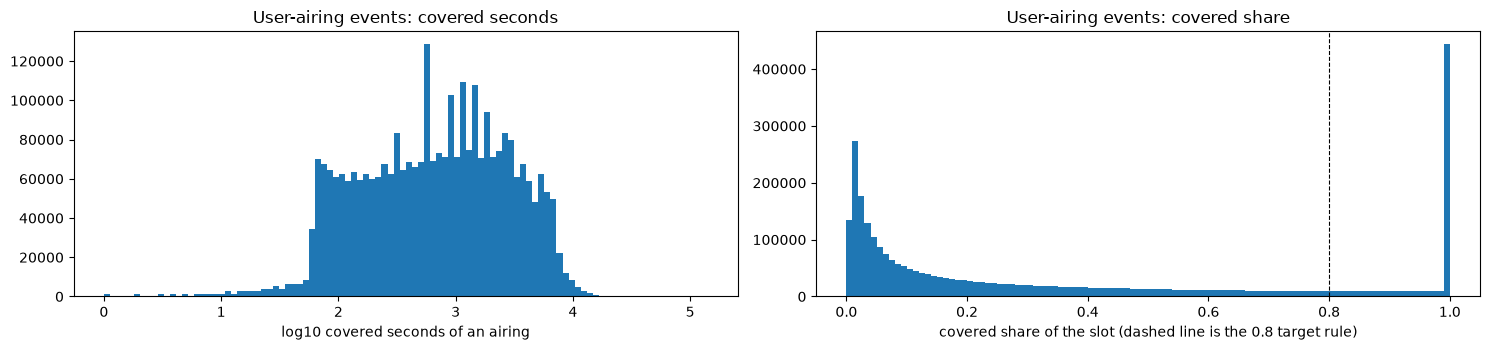

In [20]:
# Covered share of every labelled airing per user (the screen time of the target rule)
lab_slots = train_slots[train_slots.labelled].reset_index(drop=True)
ua = join.user_airings(views, lab_slots)
ua['window'] = np.where(ua.week <= 20, 'W1', 'W2')
print(f'{len(ua):,} user-airing events, {ua.user_id.nunique():,} users, {ua.tv_show_id.nunique():,} programmes')
display(pd.DataFrame({'covered seconds': quantiles(ua.sec, 'sec'), 'covered share of slot': quantiles(ua.frac, 'frac'),
                      'views per event': quantiles(ua.n_views, 'n_views')}).T.round(3))
ua['slot_len'] = pd.cut(ua.duration / 60, [0, 10, 30, 60, 120, 10**6], labels=['up to 10 min', '10 to 30 min', '30 to 60 min', '1 to 2 h', 'over 2 h'])
by_len = ua.groupby('slot_len', observed=True).agg(events=('frac', 'size'), median_share=('frac', 'median'),
                                                   share_at_least_08=('frac', lambda s: (s >= 0.8).mean()))
display(by_len.round(3))
print('share of labelled viewing seconds that falls in airings covered at least 0.8:',
      round(ua.sec[ua.frac >= 0.8].sum() / ua.sec.sum(), 4))
fig, ax = plt.subplots(1, 2, figsize=(15, 3.6))
ax[0].hist(np.log10(ua.sec), bins=100)
ax[0].set_xlabel('log10 covered seconds of an airing')
ax[0].set_title('User-airing events: covered seconds')
ax[1].hist(ua.frac, bins=100)
ax[1].axvline(0.8, color='k', ls='--', lw=0.8)
ax[1].set_xlabel('covered share of the slot (dashed line is the 0.8 target rule)')
ax[1].set_title('User-airing events: covered share')
savefig('airing_coverage')

In [21]:
# Sensitivity of the interaction set to the watched threshold
rules = {
    'any overlap': ua.sec > 0,
    '>= 300 s': ua.sec >= 300,
    '>= 50% of slot': ua.frac >= 0.5,
    '>= 80% of slot (target rule)': ua.frac >= 0.8,
    '>= 95% of slot': ua.frac >= 0.95,
}
rows = []
for name, mask in rules.items():
    e = ua[mask]
    pairs = e.groupby(['user_id', 'tv_show_id']).size()
    per_u = pairs.groupby(level=0).size()
    rows.append({'rule': name, 'user-airing events': int(mask.sum()), 'user-programme pairs': len(pairs),
                 'users': len(per_u), 'test users': int(per_u.index.isin(test_users).sum()),
                 'users with >= 5 programmes': int((per_u >= 5).sum()), 'programmes': e.tv_show_id.nunique(),
                 'median programmes per user': per_u.median()})
sens = pd.DataFrame(rows).set_index('rule')
SUMMARY['threshold_sensitivity'] = sens.to_dict(orient='index')
sens

,user-airing events,user-programme pairs,users,test users,users with >= 5 programmes,programmes,median programmes per user
rule,,,,,,,
any overlap,3014129,1371685,4895,1258,4874,4363,249.0
>= 300 s,2079171,949556,4890,1258,4856,4276,171.0
>= 50% of slot,940359,368703,4871,1256,4766,4071,58.0
>= 80% of slot (target rule),615979,230113,4841,1256,4633,3867,33.0
>= 95% of slot,482230,172963,4805,1252,4458,3716,22.0


## 5. The competition target, rebuilt on the training weeks

window,W1,W2
qualifying airings,319771.0,296208.0
user-programme pairs,116194.0,141105.0
users with any,4737.0,4643.0
users with at least 5 (have a target),4349.0,4030.0
test users with at least 5,1197.0,1150.0
median qualifying programmes per user,20.0,17.0
median qualifying airings per user,46.0,34.0


,count,mean,std,min,10%,25%,50%,75%,90%,max
rank (0 is #1),,,,,,,,,,
0,4030.0,14.5,23.7,1.0,2.0,4.0,8.0,16.0,31.0,390.0
1,4030.0,7.9,11.3,1.0,1.0,2.0,4.0,9.0,18.0,187.0
2,4030.0,5.2,6.8,1.0,1.0,2.0,3.0,6.0,11.0,90.0
3,4030.0,3.8,4.9,1.0,1.0,1.0,2.0,4.0,8.0,86.0
4,4030.0,3.0,3.7,1.0,1.0,1.0,2.0,3.0,6.0,68.0
5,3877.0,2.5,2.8,1.0,1.0,1.0,2.0,3.0,5.0,37.0


W2 users with a 6th programme: 3877, of them the 5th and 6th have equal frequency: 0.679
W2 users whose #5 programme has frequency 1: 0.42


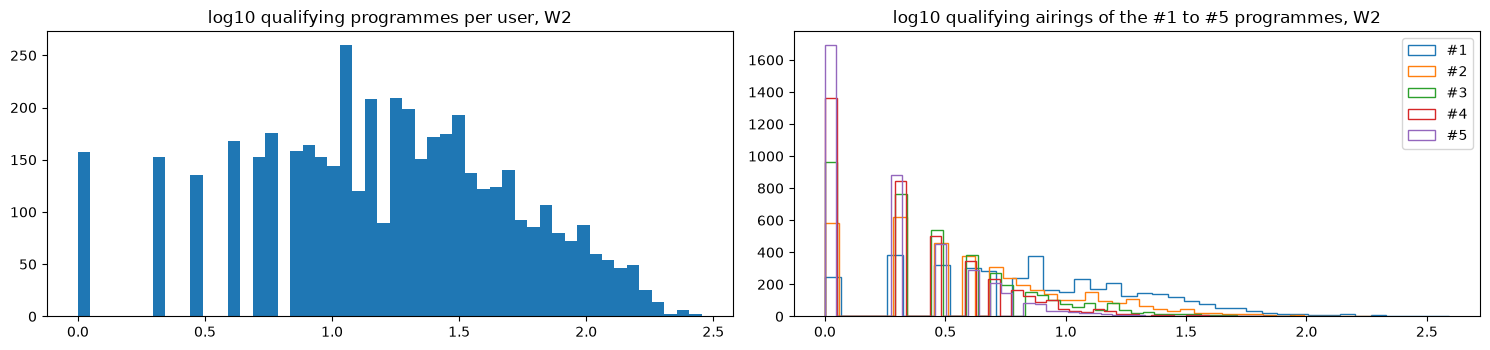

In [22]:
# Target rule applied separately to W1 and W2
freq = {w: target.frequency(ua[ua.window == w]) for w in ['W1', 'W2']}
tops = {w: target.top_k(freq[w]) for w in freq}
rows = []
for w in freq:
    per_u = freq[w].groupby('user_id').size()
    rows.append({'window': w, 'qualifying airings': int(freq[w].freq.sum()), 'user-programme pairs': len(freq[w]),
                 'users with any': len(per_u), 'users with at least 5 (have a target)': len(tops[w]),
                 'test users with at least 5': int(tops[w].index.isin(test_users).sum()),
                 'median qualifying programmes per user': per_u.median(),
                 'median qualifying airings per user': freq[w].groupby('user_id').freq.sum().median()})
tgt_stats = pd.DataFrame(rows).set_index('window')
SUMMARY['target_windows'] = tgt_stats.to_dict(orient='index')
display(tgt_stats.T)
r = target.ranked(freq['W2'])
r = r[r.user_id.isin(tops['W2'].index) & (r['rank'] < 6)]
display(r.groupby('rank').freq.describe(percentiles=[.1, .25, .5, .75, .9]).round(1).rename_axis('rank (0 is #1)'))
p = r.pivot_table(index='user_id', columns='rank', values='freq')
has6 = p[5].notna()
tie56 = float((p.loc[has6, 4] == p.loc[has6, 5]).mean())
print(f'W2 users with a 6th programme: {int(has6.sum())}, of them the 5th and 6th have equal frequency: {tie56:.3f}')
print('W2 users whose #5 programme has frequency 1:', round(float((p[4] == 1).mean()), 3))
SUMMARY['target_ties'] = {'share_5th_equals_6th': tie56, 'users_with_6th': int(has6.sum())}
fig, ax = plt.subplots(1, 2, figsize=(15, 3.6))
ax[0].hist(np.log10(freq['W2'].groupby('user_id').size()), bins=50)
ax[0].set_title('log10 qualifying programmes per user, W2')
for k in range(5):
    ax[1].hist(np.log10(p[k]), bins=40, histtype='step', label=f'#{k + 1}')
ax[1].legend()
ax[1].set_title('log10 qualifying airings of the #1 to #5 programmes, W2')
savefig('target_frequencies')
del p

In [23]:
# Which programmes form the targets
tw2 = explode_top(tops['W2'])
member = tw2.tv_show_id.value_counts()
w2_air = lab[(lab.week >= 21) & (lab.week <= 30)].groupby('tv_show_id').agg(airings_w2=('start', 'size'), channels_w2=('channel_id', 'nunique'))
top_t = member.head(25).to_frame('users with it in the W2 target').join(prog[['title', 'category', 'median_slot_min']]).join(w2_air)
top_t['share of target users'] = top_t['users with it in the W2 target'] / len(tops['W2'])
display(top_t.round(3))
print('distinct programmes in W2 targets', len(member), '| top 10 programmes cover', round(member.head(10).sum() / member.sum(), 3),
      'of target slots | top 50 cover', round(member.head(50).sum() / member.sum(), 3))
q2 = freq['W2']
cmp = pd.DataFrame({
    'target pairs': tw2.tv_show_id.map(prog.category).value_counts(normalize=True),
    'qualifying pairs': q2.tv_show_id.map(prog.category).value_counts(normalize=True),
    'labelled airtime W2': lab[(lab.week >= 21) & (lab.week <= 30)].groupby('tv_show_category').duration.sum().pipe(lambda s: s / s.sum()),
}).round(3).sort_values('target pairs', ascending=False)
display(cmp.T)
display(pd.DataFrame({
    'target programmes, median slot minutes': quantiles(tw2.tv_show_id.map(prog.median_slot_min), 'a'),
    'qualifying programmes, median slot minutes': quantiles(q2.tv_show_id.map(prog.median_slot_min), 'b'),
    'target programmes, airings in W2': quantiles(tw2.tv_show_id.map(w2_air.airings_w2), 'c'),
    'qualifying programmes, airings in W2': quantiles(q2.tv_show_id.map(w2_air.airings_w2), 'd'),
}).T.round(1))

,users with it in the W2 target,title,category,median_slot_min,airings_w2,channels_w2,share of target users
tv_show_id,,,,,,,
2400480,2011,'ТСН. Неделя'.,Инфо,60.0,1183,3,0.499
240081,1691,Факты. День.,Инфо,25.0,453,1,0.420
2400508,897,Сегодня. Итоги с Олегом Панютой.,Инфо,30.0,344,1,0.223
12001682,845,М/с 'Губка Боб Квадратные Штаны'.,Детям,20.0,6137,8,0.210
20088,754,'Завтрак с 1+1'. Информационно-развлекательная программа.,Развлечения,50.0,250,2,0.187
2400467,688,'Викна-Новости'.,Инфо,40.0,186,1,0.171
12002856,369,М/с 'Элвин и бурундуки'.,Детям,12.0,1879,5,0.092
12001734,299,"М/с 'Волшебные покровители', 154 с. 'Хочу это вырезать / Мэрский д...",Детям,20.0,1440,4,0.074
1100411,298,Премьера. 'Вещдок. Особый случай. Око за око'.,Познавательное,80.0,147,1,0.074


distinct programmes in W2 targets 1488 | top 10 programmes cover 0.404 of target slots | top 50 cover 0.672


,Инфо,Фильмы,Детям,Сериалы,Развлечения,Познавательное,Другое,Спорт
target pairs,0.281,0.195,0.183,0.136,0.132,0.057,0.016,NaN
qualifying pairs,0.092,0.544,0.093,0.104,0.108,0.046,0.013,NaN
labelled airtime W2,0.026,0.425,0.153,0.288,0.066,0.039,0.003,0.0


,q0,q0.01,q0.05,q0.1,q0.25,q0.5,q0.75,q0.9,q0.95,q0.99,q0.999,q1
"target programmes, median slot minutes",4.0,4.0,12.0,20.0,25.0,50.0,95.0,120.0,130.0,164.0,220.0,260.0
"qualifying programmes, median slot minutes",4.0,5.0,20.0,25.0,50.0,95.0,110.0,125.0,140.0,180.0,235.0,372.5
"target programmes, airings in W2",1.0,2.0,4.0,8.0,42.0,250.0,892.0,1440.0,2861.0,6137.0,6137.0,6137.0
"qualifying programmes, airings in W2",1.0,1.0,2.0,2.0,6.0,18.0,131.0,453.0,1183.0,4343.0,6137.0,6137.0


In [24]:
# More airings give more chances: qualifying frequency against the number of airings in the window
q2a = q2.assign(airings=q2.tv_show_id.map(w2_air.airings_w2))
q2a['airings_bin'] = pd.qcut(q2a.airings, 6, duplicates='drop')
display(q2a.groupby('airings_bin', observed=True).agg(pairs=('freq', 'size'), median_freq=('freq', 'median'),
                                                     mean_freq=('freq', 'mean')).round(2))
print('Spearman correlation of frequency with airings:', round(q2a[['freq', 'airings']].corr(method='spearman').iloc[0, 1], 3))
del q2a

,pairs,median_freq,mean_freq
airings_bin,,,
"(0.999, 4.0]",28382,1.0,1.06
"(4.0, 9.0]",21393,1.0,1.09
"(9.0, 18.0]",21908,1.0,1.09
"(18.0, 59.0]",23009,1.0,1.39
"(59.0, 250.0]",23231,1.0,2.37
"(250.0, 6137.0]",23182,2.0,5.69


Spearman correlation of frequency with airings: 0.509


## 6. How stable the target is over time

In [25]:
# Previous-window target as a prediction of the next-window target (W1 to W2)
common = tops['W1'].index.intersection(tops['W2'].index)
overlap = pd.Series([len(set(tops['W1'][u]) & set(tops['W2'][u])) for u in common], index=common)
prev_map = target.mapk(tops['W2'].loc[common], tops['W1'].to_dict())
print(f'users with a target in both windows: {len(common)} | MAP@5 of the W1 top-5 on the W2 target: {prev_map:.4f}')
display(overlap.value_counts(normalize=True).sort_index().round(3).to_frame('share of users').T.rename_axis(columns='programmes shared by the two top-5 lists'))
act = per_user.loc[common, 'hours']
terc = pd.qcut(act, 3, labels=['light', 'medium', 'heavy'])
display(pd.DataFrame({t_: {'users': int((terc == t_).sum()),
                           'MAP@5': target.mapk(tops['W2'].loc[terc.index[terc == t_]], tops['W1'].to_dict()),
                           'mean shared': overlap[terc == t_].mean()} for t_ in ['light', 'medium', 'heavy']}).round(4))
SUMMARY['stability'] = {'users_both': len(common), 'map5_prev_top5': prev_map, 'mean_shared': float(overlap.mean())}

users with a target in both windows: 3812 | MAP@5 of the W1 top-5 on the W2 target: 0.3129


programmes shared by the two top-5 lists,0,1,2,3,4,5
share of users,0.171,0.24,0.287,0.212,0.08,0.01


,light,medium,heavy
users,1271.0000,1270.0000,1271.0000
MAP@5,0.1997,0.3118,0.4273
mean shared,1.2415,1.8134,2.4091


In [26]:
# Five-week blocks: how fast the predictive value of a past top-5 decays
BLOCKS = {'B1 (11-15)': (11, 15), 'B2 (16-20)': (16, 20), 'B3 (21-25)': (21, 25), 'B4 (26-30)': (26, 30)}
btops = {b: target.top_k(target.frequency(ua[(ua.week >= lo) & (ua.week <= hi)])) for b, (lo, hi) in BLOCKS.items()}
names = list(BLOCKS)
mat = pd.DataFrame(index=names, columns=names, dtype=float)
for i, bi in enumerate(names):
    for bj in names[i + 1:]:
        users = btops[bj].index.intersection(btops[bi].index)
        mat.loc[bi, bj] = target.mapk(btops[bj].loc[users], btops[bi].to_dict())
display(mat.round(4).rename_axis(index='history block', columns='target block'))
cum_rows = {}
for j, bj in enumerate(names[1:], start=1):
    lo_j = BLOCKS[bj][0]
    hist_top = target.top_k(target.frequency(ua[ua.week < lo_j]), strict=False)
    last_top = target.top_k(target.frequency(ua[(ua.week >= lo_j - 5) & (ua.week < lo_j)]), strict=False)
    users = btops[bj].index.intersection(hist_top.index)
    cum_rows[bj] = {'all earlier weeks': target.mapk(btops[bj].loc[users], hist_top.to_dict()),
                    'only the previous 5 weeks': target.mapk(btops[bj].loc[users], last_top.to_dict()), 'users': len(users)}
display(pd.DataFrame(cum_rows).T.round(4))
SUMMARY['block_decay'] = mat.round(4).to_dict()

target block,B1 (11-15),B2 (16-20),B3 (21-25),B4 (26-30)
history block,,,,
B1 (11-15),NaN,0.3372,0.2705,0.2338
B2 (16-20),NaN,NaN,0.2947,0.2411
B3 (21-25),NaN,NaN,NaN,0.2701
B4 (26-30),NaN,NaN,NaN,NaN


,all earlier weeks,only the previous 5 weeks,users
B2 (16-20),0.3141,0.3141,3716.0
B3 (21-25),0.3076,0.2809,2540.0
B4 (26-30),0.2742,0.1838,3633.0


In [27]:
# Why W1 target programmes leave the W2 target: schedule changes against changes in the user
w1_air = lab[lab.week <= 20].groupby('tv_show_id').size()
t1 = explode_top(tops['W1'].loc[common])
t1 = t1.merge(tw2.assign(in_w2_target=True), how='left', on=['user_id', 'tv_show_id'])
t1 = t1.merge(q2[['user_id', 'tv_show_id']].assign(qualifies_w2=True), how='left', on=['user_id', 'tv_show_id'])
t1[['in_w2_target', 'qualifies_w2']] = t1[['in_w2_target', 'qualifies_w2']].fillna(False).astype(bool)
t1['airing_ratio'] = t1.tv_show_id.map(w2_air.airings_w2).fillna(0) / t1.tv_show_id.map(w1_air)
t1['ratio_bin'] = pd.cut(t1.airing_ratio, [-0.01, 0, 0.5, 0.9, 1.1, 2, np.inf],
                         labels=['stopped airing', 'under half', '0.5 to 0.9', 'about the same', '1.1 to 2', 'over 2'])
display(t1.groupby('ratio_bin', observed=True).agg(pairs=('tv_show_id', 'size'), share_still_in_target=('in_w2_target', 'mean'),
                                                   share_still_qualifying=('qualifies_w2', 'mean')).round(3)
        .rename_axis('W2 airings over W1 airings'))

,pairs,share_still_in_target,share_still_qualifying
W2 airings over W1 airings,,,
stopped airing,810,0.000,0.000
under half,2011,0.034,0.172
0.5 to 0.9,1823,0.180,0.352
about the same,11201,0.503,0.718
1.1 to 2,2685,0.322,0.488
over 2,530,0.087,0.242


## 7. The test window schedule

,value
programmes airing in w31_42,6642.0000
of them aired in weeks 11 to 30,0.7838
of them watched at 0.8 by someone in training,0.4298
labelled airings of programmes aired in training,0.9565


week,31,32,33,34,35,36,37,38,39,40,41,42
airings,12328.000,11911.000,11646.000,11619.000,12728.000,12376.000,11738.000,12062.000,11992.000,11870.000,12199.00,12315.000
programmes,1933.000,1624.000,1707.000,1615.000,2059.000,1885.000,1627.000,1577.000,1600.000,1508.000,1741.00,1712.000
new_share,0.035,0.022,0.032,0.041,0.049,0.047,0.039,0.046,0.041,0.051,0.06,0.057


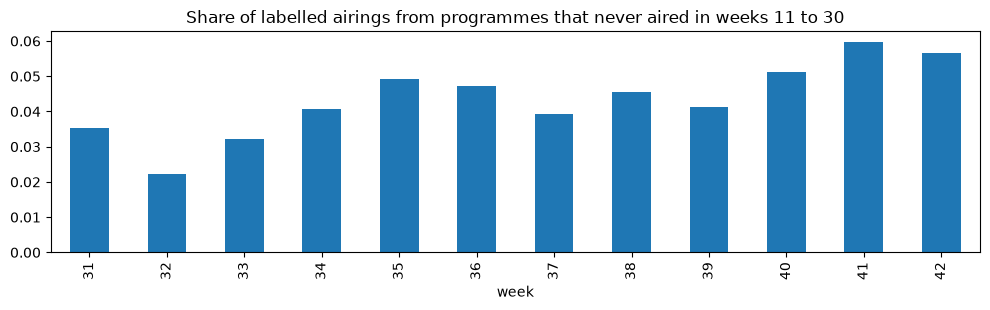

In [28]:
# Programmes airing in weeks 31 to 42: churn against training and the start of the autumn season
lab31 = lab[(lab.week >= 31) & (lab.week <= 42)]
aired_train = set(lab.tv_show_id[lab.week <= 30])
seen_q = set(pd.concat([freq['W1'].tv_show_id, freq['W2'].tv_show_id]))
air31 = lab31.groupby('tv_show_id').size()
t31 = {
    'programmes airing in w31_42': len(air31),
    'of them aired in weeks 11 to 30': float(air31.index.isin(aired_train).mean()),
    'of them watched at 0.8 by someone in training': float(air31.index.isin(seen_q).mean()),
    'labelled airings of programmes aired in training': float(lab31.tv_show_id.isin(aired_train).mean()),
}
display(pd.Series(t31).to_frame('value').round(4))
by_week = lab31.groupby('week').agg(airings=('tv_show_id', 'size'), programmes=('tv_show_id', 'nunique'),
                                    new_share=('tv_show_id', lambda s: (~s.isin(aired_train)).mean()))
display(by_week.T.round(3))
fig, ax = plt.subplots(figsize=(10, 3.2))
by_week.new_share.plot.bar(ax=ax, title='Share of labelled airings from programmes that never aired in weeks 11 to 30')
savefig('test_window_new_programmes')
SUMMARY['test_window'] = t31

In [29]:
# Test users: does their history still air in weeks 31 to 42, and how often compared with W2
hist_t = pd.concat([freq['W1'], freq['W2']]).groupby(['user_id', 'tv_show_id']).freq.sum().reset_index()
hist_t = hist_t[hist_t.user_id.isin(test_users)]
w2_rate = w2_air.airings_w2 / 10
w31_rate = air31 / 12
hist_t['airs_in_test'] = hist_t.tv_show_id.isin(air31.index)
hist_t['rate_ratio'] = hist_t.tv_show_id.map(w31_rate).fillna(0) / hist_t.tv_show_id.map(w2_rate)
per_t = hist_t.groupby('user_id').agg(n=('tv_show_id', 'size'), n_airing=('airs_in_test', 'sum'))
tt = {
    'test users with any qualifying programme in weeks 11 to 30': len(per_t),
    'test users with at least 5': int((per_t.n >= 5).sum()),
    'test users with at least 5 that still air in w31_42': int((per_t.n_airing >= 5).sum()),
    'share of their qualifying programmes still airing': float(hist_t.airs_in_test.mean()),
}
display(pd.Series(tt).to_frame('value').round(4))
t2 = explode_top(tops['W2'][tops['W2'].index.isin(test_users)])
t2['rate_ratio'] = t2.tv_show_id.map(w31_rate).fillna(0) / t2.tv_show_id.map(w2_rate)
display(quantiles(t2.rate_ratio, 'weekly airings in w31_42 over W2, test users W2 top-5').to_frame().T.round(2))
print('share of test users W2 top-5 programmes that stop airing in w31_42:', round(float((t2.rate_ratio == 0).mean()), 3))
SUMMARY['test_users_history'] = tt

,value
test users with any qualifying programme in weeks 11 to 30,1256.0000
test users with at least 5,1241.0000
test users with at least 5 that still air in w31_42,1238.0000
share of their qualifying programmes still airing,0.8786


,q0,q0.01,q0.05,q0.1,q0.25,q0.5,q0.75,q0.9,q0.95,q0.99,q0.999,q1
"weekly airings in w31_42 over W2, test users W2 top-5",0.0,0.0,0.19,0.52,0.87,1.0,1.03,1.2,1.45,2.78,7.4,10.83


share of test users W2 top-5 programmes that stop airing in w31_42: 0.03


## 8. Where the target programmes come from

In [30]:
# Candidate coverage: which sources contain the W2 target programmes of users with W1 history
w1_any = ua[ua.window == 'W1'][['user_id', 'tv_show_id']].drop_duplicates()
users_h = tops['W2'].index.intersection(w1_any.user_id.unique())
tw2h = tw2[tw2.user_id.isin(users_h)].copy()
tw2h['in_w1_qualifying'] = tw2h.merge(freq['W1'][['user_id', 'tv_show_id']].assign(x=True), how='left', on=['user_id', 'tv_show_id']).x.fillna(False).astype(bool).to_numpy()
tw2h['in_w1_any_overlap'] = tw2h.merge(w1_any.assign(x=True), how='left', on=['user_id', 'tv_show_id']).x.fillna(False).astype(bool).to_numpy()
w1_views = views[views.week <= 20]
uch = w1_views.groupby(['user_id', 'vsetv_id']).duraton.sum().reset_index().sort_values(['user_id', 'duraton'], ascending=[True, False])
uch['rank'] = uch.groupby('user_id').cumcount()
top3 = uch[uch['rank'] < 3][['user_id', 'vsetv_id']].rename(columns={'vsetv_id': 'channel_id'})
chan_prog_w2 = lab[(lab.week >= 21) & (lab.week <= 30)][['channel_id', 'tv_show_id']].drop_duplicates()
on_top3 = top3.merge(chan_prog_w2, on='channel_id')[['user_id', 'tv_show_id']].drop_duplicates().assign(x=True)
tw2h['on_top3_channels'] = tw2h.merge(on_top3, how='left', on=['user_id', 'tv_show_id']).x.fillna(False).astype(bool).to_numpy()
pop_w1 = explode_top(tops['W1']).tv_show_id.value_counts()
tw2h['in_global_top50'] = tw2h.tv_show_id.isin(pop_w1.index[:50])
src = ['in_w1_qualifying', 'in_w1_any_overlap', 'on_top3_channels', 'in_global_top50']
cov = tw2h[src].mean()
cov['any of these'] = tw2h[src].any(axis=1).mean()
cov['W1 qualifying or global top 50'] = (tw2h.in_w1_qualifying | tw2h.in_global_top50).mean()
display(cov.round(4).to_frame(f'share of W2 target pairs ({len(tw2h)} pairs, {len(users_h)} users)').T)
SUMMARY['candidate_coverage'] = cov.round(4).to_dict()

,in_w1_qualifying,in_w1_any_overlap,on_top3_channels,in_global_top50,any of these,W1 qualifying or global top 50
"share of W2 target pairs (20005 pairs, 4001 users)",0.5125,0.6584,0.494,0.607,0.8101,0.6607


In [31]:
# Popularity lists and the user's own history on the W2 target (diagnostic, not the formal hold-out)
aired_w2 = set(w2_air.index)
pop_q = freq['W1'].groupby('tv_show_id').user_id.nunique().sort_values(ascending=False)
pop_f = freq['W1'].groupby('tv_show_id').freq.sum().sort_values(ascending=False)
own = target.top_k(freq['W1'], strict=False)


def fill(lst, filler):
    out = [p for p in lst if p in aired_w2][:5]
    for p_ in filler:
        if len(out) == 5:
            break
        if p_ not in out:
            out.append(p_)
    return out


lists = {
    'global top-5 by W1 target membership': list(pop_w1.index[:5]),
    'global top-5 by W1 qualifying users': list(pop_q.index[:5]),
    'global top-5 by W1 qualifying airings': list(pop_f.index[:5]),
}
truth = tops['W2']
diag = {name: target.mapk(truth, {u: lst for u in truth.index}) for name, lst in lists.items()}
filler = [p_ for p_ in pop_q.index if p_ in aired_w2]
diag['own W1 top-5 still airing, then popular'] = target.mapk(truth, {u: fill(own.get(u, []), filler) for u in truth.index})
own_all = freq['W1'].sort_values(['user_id', 'freq'], ascending=[True, False]).groupby('user_id').tv_show_id.apply(list)
diag['own W1 programmes by frequency, still airing, then popular'] = target.mapk(truth, {u: fill(own_all.get(u, []), filler) for u in truth.index})
display(pd.Series(diag).round(4).to_frame(f'MAP@5 on the W2 target ({len(truth)} users)'))
SUMMARY['diagnostic_map5'] = diag

,MAP@5 on the W2 target (4030 users)
global top-5 by W1 target membership,0.2341
global top-5 by W1 qualifying users,0.2141
global top-5 by W1 qualifying airings,0.2368
"own W1 top-5 still airing, then popular",0.3063
"own W1 programmes by frequency, still airing, then popular",0.3115


In [32]:
# Channel structure of the target: are a user's five programmes on their favourite channels
q2_air = ua[(ua.window == 'W2') & (ua.frac >= 0.8)]
main_ch = q2_air.groupby(['user_id', 'tv_show_id', 'channel_id']).size().reset_index(name='n').sort_values('n', ascending=False)
main_ch = main_ch.drop_duplicates(['user_id', 'tv_show_id'])
tch = tw2.merge(main_ch[['user_id', 'tv_show_id', 'channel_id']], on=['user_id', 'tv_show_id'], how='left')
display(quantiles(tch.groupby('user_id').channel_id.nunique(), 'distinct channels in a user W2 top-5').to_frame().T)
tch = tch.merge(uch[['user_id', 'vsetv_id', 'rank']].rename(columns={'vsetv_id': 'channel_id'}), on=['user_id', 'channel_id'], how='left')
print('W2 target pairs on the user W1 top-1 channel', round(float((tch['rank'] == 0).mean()), 3),
      '| on the top-3', round(float((tch['rank'] < 3).mean()), 3), '| on a channel never watched in W1', round(float(tch['rank'].isna().mean()), 3))

,q0,q0.01,q0.05,q0.1,q0.25,q0.5,q0.75,q0.9,q0.95,q0.99,q0.999,q1
distinct channels in a user W2 top-5,1.0,1.0,2.0,2.0,3.0,3.0,4.0,5.0,5.0,5.0,5.0,5.0


W2 target pairs on the user W1 top-1 channel 0.239 | on the top-3 0.473 | on a channel never watched in W1 0.062


In [33]:
# Content signal: do new target programmes share the category or genres of the user's history
new_t = tw2h[~tw2h.in_w1_qualifying].copy()
q1c = freq['W1'].assign(category=freq['W1'].tv_show_id.map(prog.category))
top_cat = q1c.groupby(['user_id', 'category']).freq.sum().reset_index().sort_values('freq', ascending=False).drop_duplicates('user_id').set_index('user_id').category
new_t['category'] = new_t.tv_show_id.map(prog.category)
new_t['user_top_category'] = new_t.user_id.map(top_cat)
base = tw2.tv_show_id.map(prog.category).value_counts(normalize=True)
expected = float(new_t.user_top_category.map(base).mean())
print(f'new W2 target pairs (not qualifying in W1): {len(new_t)} of {len(tw2h)}')
print('share whose category equals the user top W1 category:', round(float((new_t.category == new_t.user_top_category).mean()), 3),
      '| expected from category popularity alone:', round(expected, 3))
gen = prog[['genre_1', 'genre_2', 'genre_3']].apply(lambda r_: {g_ for g_ in r_ if isinstance(g_, str)}, axis=1)
user_genres = freq['W1'].assign(g=freq['W1'].tv_show_id.map(gen)).groupby('user_id').g.apply(lambda s: set().union(*s))
has_g = new_t.tv_show_id.map(gen).apply(len) > 0
shared = [len(gen[p_] & user_genres.get(u, set())) > 0 for u, p_ in zip(new_t.user_id[has_g], new_t.tv_show_id[has_g])]
perm = pd.Series(np.random.default_rng(0).permutation(user_genres.index), index=user_genres.index)
shared_perm = [len(gen[p_] & user_genres.get(perm.get(u, u), set())) > 0 for u, p_ in zip(new_t.user_id[has_g], new_t.tv_show_id[has_g])]
print('new target pairs with genres:', int(has_g.sum()), '| share sharing a genre with the user W1 history:', round(float(np.mean(shared)), 3),
      '| with the history of a random other user:', round(float(np.mean(shared_perm)), 3))

new W2 target pairs (not qualifying in W1): 9752 of 20005
share whose category equals the user top W1 category: 0.231 | expected from category popularity alone: 0.216


new target pairs with genres: 9694 | share sharing a genre with the user W1 history: 0.829 | with the history of a random other user: 0.797


In [34]:
# Viewing habits by channel, weekday and hour, from all airtime: how many target programmes air in the user's habitual cells
w1v = views[views.week <= 20]
h0, h1 = w1v.start.to_numpy() // 3600, (w1v.stop.to_numpy() - 1) // 3600
n_h = h1 - h0 + 1
rep = np.repeat(np.arange(len(w1v)), n_h)
hour_ = h0[rep] + np.arange(n_h.sum()) - np.repeat(np.cumsum(n_h) - n_h, n_h)
sec_ = np.minimum(w1v.stop.to_numpy()[rep], (hour_ + 1) * 3600) - np.maximum(w1v.start.to_numpy()[rep], hour_ * 3600)


def hour_of_week(hours):
    # day 0 of the clock is 1970-01-01, a Thursday, so the weekday is shifted by 3 (Monday is 0)
    return ((hours // 24 + 3) % 7) * 24 + hours % 24


habit = (pd.DataFrame({'user_id': w1v.user_id.to_numpy()[rep], 'channel_id': w1v.vsetv_id.to_numpy()[rep],
                       'how': hour_of_week(hour_), 'sec': sec_})
         .groupby(['user_id', 'channel_id', 'how']).sec.sum().reset_index())
del rep, hour_, sec_
w2_slots = lab[(lab.week >= 21) & (lab.week <= 30)][['channel_id', 'start', 'tv_show_id']].copy()
w2_slots['how'] = hour_of_week(w2_slots.start // 3600)
cell_prog = w2_slots[['channel_id', 'how', 'tv_show_id']].drop_duplicates()
rows = {}
for thr_h in [0.5, 1, 3, 10]:
    cand = habit[habit.sec >= thr_h * 3600].merge(cell_prog, on=['channel_id', 'how'])[['user_id', 'tv_show_id']].drop_duplicates()
    hit = tw2h.merge(cand.assign(x=True), how='left', on=['user_id', 'tv_show_id']).x.fillna(False).astype(bool)
    size = cand.groupby('user_id').size().reindex(users_h).fillna(0)
    rows[f'>= {thr_h} h in the cell over W1'] = {'share of W2 target pairs covered': float(hit.mean()),
                                                 'median candidate programmes per user': float(size.median())}
display(pd.DataFrame(rows).T.round(3))
SUMMARY['habit_coverage'] = rows

,share of W2 target pairs covered,median candidate programmes per user
>= 0.5 h in the cell over W1,0.685,304.0
>= 1 h in the cell over W1,0.547,138.0
>= 3 h in the cell over W1,0.129,2.0
>= 10 h in the cell over W1,0.001,0.0


In [35]:
# Co-view structure for association rules and PageRank: support of programmes and programme pairs in W1
u_idx = pd.Index(freq['W1'].user_id.unique())
i_idx = pd.Index(freq['W1'].tv_show_id.unique())
X = sp.csr_matrix((np.ones(len(freq['W1'])), (u_idx.get_indexer(freq['W1'].user_id), i_idx.get_indexer(freq['W1'].tv_show_id))),
                  shape=(len(u_idx), len(i_idx)))
supp = np.asarray(X.sum(axis=0)).ravel()
C = (X.T @ X).tocoo()
off_diag = C.row < C.col
pair_supp = C.data[off_diag]
display(quantiles(supp, 'users per programme (W1, qualifying)').to_frame().T)
print('programmes', len(i_idx), '| with at least 20 users', int((supp >= 20).sum()), '| with at least 100 users', int((supp >= 100).sum()))
print('programme pairs with co-support >= 1', len(pair_supp), '| >= 10', int((pair_supp >= 10).sum()), '| >= 50', int((pair_supp >= 50).sum()))
print('matrix density', round(X.nnz / (X.shape[0] * X.shape[1]), 5))
del C, X

,q0,q0.01,q0.05,q0.1,q0.25,q0.5,q0.75,q0.9,q0.95,q0.99,q0.999,q1
"users per programme (W1, qualifying)",1.0,1.0,1.0,2.0,4.0,12.0,34.0,78.0,135.0,738.02,2399.192,3716.0


programmes 2500 | with at least 20 users 911 | with at least 100 users 171
programme pairs with co-support >= 1 652411 | >= 10 38598 | >= 50 4454
matrix density 0.00981


## 9. Test users without enough history

In [36]:
# Test users with fewer than five qualifying programmes in weeks 11 to 30
n_q = hist_t.groupby('user_id').size().reindex(test_users).fillna(0)
any_hist = ua[ua.user_id.isin(test_users)].groupby('user_id').tv_show_id.nunique().reindex(test_users).fillna(0)
fb = pd.DataFrame({'qualifying programmes': n_q, 'programmes with any overlap': any_hist,
                   'hours': per_user.hours.reindex(test_users).fillna(0)})
fb['group'] = pd.cut(fb['qualifying programmes'], [-1, 0, 4, np.inf], labels=['none', '1 to 4', '5 or more'])
display(fb.groupby('group', observed=False).agg(users=('hours', 'size'), median_hours=('hours', 'median'),
                                                median_any_overlap=('programmes with any overlap', 'median')).round(1))
SUMMARY['fallback'] = fb.group.value_counts().astype(int).to_dict()

,users,median_hours,median_any_overlap
group,,,
none,4,16.8,5.0
1 to 4,15,52.2,46.0
5 or more,1241,543.7,339.0


In [37]:
# Save the user-airing table for the modelling notebooks and the summary
ua.drop(columns=['slot_len']).to_parquet(os.path.join(CACHE, 'user_airings_w11_30.parquet'), index=False)
with open(os.path.join(ROOT, 'eda', 'eda_summary.json'), 'w', encoding='utf-8') as f:
    json.dump(SUMMARY, f, indent=1, default=str, ensure_ascii=False)
print(sorted(os.listdir(FIG)))
print(f'total runtime {time.time() - T0:.0f}s')

['airing_coverage.png', 'daily_activity.png', 'labelled_share_by_week.png', 'per_user.png', 'target_frequencies.png', 'test_window_new_programmes.png', 'time_alignment.png', 'view_duration.png', 'views_by_time.png']
total runtime 68s


## Findings

Data
- The log holds 5,821,987 views of 4,914 users on 202 channels from 9 March to 26 July 2020. All 1,260 test users are in it. The shortest view lasts 61 s, so the log seems to drop views of a minute or less. Timestamps are local wall-clock time: the 117 rows where duraton is one hour less than stop minus start all fall on 28 and 29 March, the daylight saving switch.
- Logging is uneven. Users per day fall from about 4,070 (March to mid-May) to 2,740 (13 May to 15 June) and 1,760 (16 June to 4 July). 3 July has no views at all, and on 5 July the level jumps back to about 3,800. 24% of the users seen both before and after the gap have no view inside it. The level changes from one day to the next, which points to missing logs and not to a change in behaviour. A target rebuilt on weeks 21 to 30 therefore comes from thinner data than the test target.
- Users watch a lot: the median is 393 hours over 20 weeks on 57 channels. Test users watch more (median 537 hours), and 1,216 of them were active in week 30.
- Only 10.8% of schedule rows and 16 to 17% of airtime carry a programme id. Labelled ids are mostly films (8,197 of 9,671), series and children's shows. News under the unlabelled title "Новости" fills 10,474 hours. Unlabelled titles rarely match a labelled title (4.4% of unlabelled airtime), so unlabelled airtime cannot be turned into items. The three schedule files never repeat a row: each ends with the broadcast day and the next continues the grid.
- The log and the schedule share one clock, since boundary hits peak at zero shift in every week. 94% of viewing time falls inside some slot and 53% inside labelled slots.

Target
- The covered share of an airing is bimodal. Most user-airing events are short zapping, and a separate spike sits at full coverage. 71% of events on slots up to 10 minutes reach 0.8, against 7% on slots over 2 hours.
- The organisers' rule gives a target to 4,349 users on weeks 11 to 20 and to 4,030 users on weeks 21 to 30. The 1,260 test users are a subset of such users.
- Frequently aired programmes dominate the target. ТСН is in the top five of 50% of target users on weeks 21 to 30 and "Факты. День" in the top five of 42%. News makes 28% of target pairs against 2.6% of labelled airtime, and the top 10 programmes fill 40% of all target slots. Films make 54% of qualifying pairs but only 19.5% of target pairs.
- Frequency grows with the number of airings (Spearman 0.51). A top-five programme of weeks 11 to 20 that stopped airing never stays in the next target. One with about the same number of airings stays in half of the cases.
- The fifth place is noisy. 42% of users have frequency 1 at place five, and 68% have a tie between places five and six. The data page does not say how ties are broken, so part of the target cannot be predicted.

Signal for the models
- Habit is the main signal. The top five of weeks 11 to 20 scores MAP@5 0.313 on the target of weeks 21 to 30, with 0.43 for heavy and 0.20 for light users. The value decays with the lag, from 0.337 for the next five weeks to 0.234 fifteen weeks later. All earlier weeks together predict at least as well as the latest five.
- Popularity alone scores from 0.21 to 0.24. Own history first, followed by popular programmes, scores about 0.31.
- 51% of target pairs on weeks 21 to 30 were already qualifying on weeks 11 to 20, 66% were at least touched, 61% are in the global top 50 and 81% are in at least one of these sources. About a fifth of the target is new to the user and not popular.
- Content attributes say little about these new programmes. The user's top category matches in 23.1% of cases against 21.6% by chance, and a shared genre appears in 82.9% against 79.7% for the history of a random other user.
- Co-viewing is dense enough at the head for association rules and PageRank. 911 programmes have at least 20 qualifying users in weeks 11 to 20, and 38,598 programme pairs share at least 10 users.
- The test schedule continues the training one. 96% of labelled airings in weeks 31 to 42 belong to programmes aired in training, 88% of the test users' qualifying programmes still air, and only 3% of their recent top-five programmes stop. 19 test users have fewer than five qualifying programmes (4 have none) and need a fallback.

Consequences for modelling
- Use the 0.8 rule for interactions and rebuild the hold-out target with the same rule, keeping the logging gap in mind. Repeats are allowed and carry most of the signal.
- Score a programme by how often the user fully watched it per airing, times the number of its airings in the target window, which the schedule gives in advance.
- Fill the remaining places with popular programmes that air in the window. Collaborative methods should aim at the fifth of the target that is new to the user. Content attributes are weak there and fit cold start better.